# Generating Lyman-$\alpha$ forest spectra with `lyaforest`

`lyaforest.compute_tau` takes skewers from any simulation (HI density, temperature and peculiar velocity along a line of sight) and returns the Lyman-$\alpha$ optical depth in each pixel. It sums Voigt profiles from every pixel along the skewer:

$$\tau(z_0) = \frac{c\, I_\alpha\, \delta x}{\sqrt{\pi}} \sum_x \frac{n_\mathrm{HI}(x)}{b(x)\,[1+z(x)]}\, H\big(a, u\big), \qquad u = \frac{v_\mathrm{pec}(x) + H(z_0)\,\Delta x/(1+z_0)}{b(x)}, \qquad a = \frac{\Gamma \lambda_\alpha}{4\pi b(x)}$$

where $\Delta x$ is the comoving separation between pixel $x$ and the pixel at $z_0$, wrapped around the box when it is periodic, $b = \sqrt{2 k_B T / m_\mathrm{H}}$ is the thermal Doppler parameter and the Voigt function $H(a,u) = \mathrm{Re}\,[w(u + ia)]$ is computed with the Faddeeva function `scipy.special.wofz`.

In [8]:
import shutil

import numpy as np
import matplotlib.pyplot as plt

import lyaforest

# Colours: ink for the input fields, blue for lyaforest, orange for the simulation
INK, INK_LIGHT, GRID = '#0b0b0b', '#52514e', '#e6e5e0'
BLUE, ORANGE = '#2a78d6', '#eb6834'

plt.rcParams.update({
    'text.usetex': shutil.which('latex') is not None, # Use LaTeX only if installed
    'font.family': 'serif',
    'mathtext.fontset': 'cm',
    'font.size': 13,
    'axes.labelsize': 14,
    'axes.titlesize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
    'legend.frameon': False,
    'lines.linewidth': 1.5,
    'axes.linewidth': 0.8,
    'axes.edgecolor': INK_LIGHT,
    'axes.labelcolor': INK,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'axes.axisbelow': True,
    'grid.color': GRID,
    'grid.linewidth': 0.6,
    'xtick.color': INK_LIGHT,
    'ytick.color': INK_LIGHT,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.major.size': 4,
    'ytick.major.size': 4,
    'xtick.minor.size': 2,
    'ytick.minor.size': 2,
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,
    'figure.dpi': 110,
    'savefig.bbox': 'tight',
    'savefig.dpi': 200,
})

## 1. Any skewer: a single absorber

`compute_tau` only needs arrays. Here we build a skewer by hand: an almost empty box at $z = 3$ with one dense, hot pixel in the middle.

| Argument | Units |
|---|---|
| `n_HI` | proper cm$^{-3}$ |
| `T` | K |
| `v_pec` | km s$^{-1}$ |
| `z` | redshift of each pixel, or one value for the whole skewer |
| `L_box` | cMpc/$h$ |

The cosmology (`hubble_param`, `omega_m`, `omega_l`) and `periodic=True` can also be set.

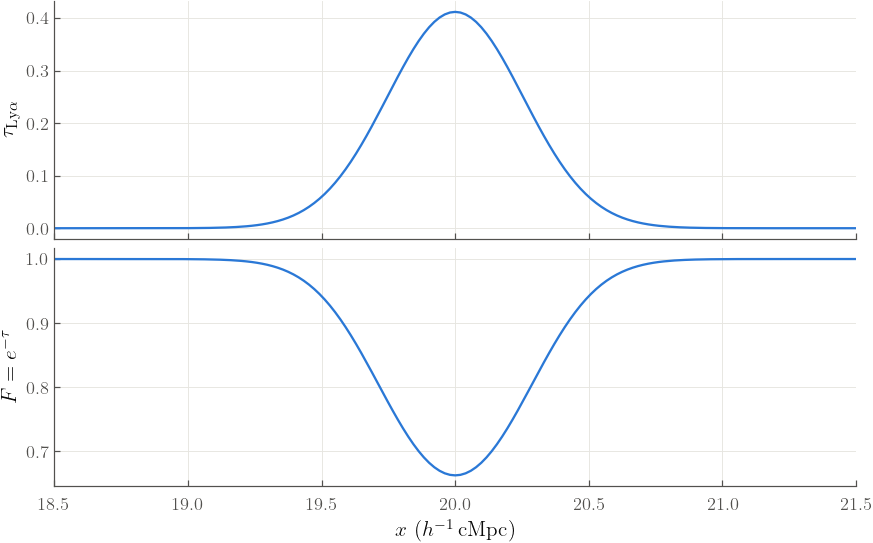

In [9]:
N_pixel = 2048
L_box = 40.0 # cMpc/h

n_HI = np.full(N_pixel, 1e-20)  # cm^-3
T = np.full(N_pixel, 100.0)     # K
v_pec = np.zeros(N_pixel)       # km/s

n_HI[N_pixel // 2] = 1e-9
T[N_pixel // 2] = 1e5

tau = lyaforest.compute_tau(n_HI, T, v_pec, z=3.0, L_box=L_box)

x = np.arange(N_pixel) * L_box / N_pixel # comoving position, cMpc/h

fig, ax = plt.subplots(nrows=2, sharex=True, figsize=(8, 5), layout='constrained')
ax[0].plot(x, tau, c=BLUE)
ax[1].plot(x, np.exp(-tau), c=BLUE)
ax[0].set_ylabel(r'$\tau_\mathrm{Ly\alpha}$')
ax[1].set_ylabel(r'$F = e^{-\tau}$')
ax[1].set_xlabel(r'$x\ (h^{-1}\,\mathrm{cMpc})$')
ax[1].set_xlim(18.5, 21.5)
fig.align_ylabels(ax)
plt.show()

## 2. Skewers from a simulation

`read_skewer` reads the simulation output used in the tutorial. By default it reads the small example dataset in `example_data/` (snapshots at $z = 2, 3, 4, 5$, 10 skewers each); pass `data_file='Spectra_Fields.npy'` for the full output. For another simulation, load its skewers however you like and pass the arrays to `compute_tau`.

In [10]:
skewer = lyaforest.read_skewer(redshift_key='2.0', skewer_indx=0)

tau = lyaforest.compute_tau(skewer['n_HI'], skewer['T'], skewer['v_pec'], skewer['z'], L_box=skewer['L_box'])
tau_sim = skewer['tau_sim'] # optical depth computed by the simulation code, for comparison

From top to bottom: HI number density, gas temperature, peculiar velocity, optical depth, transmitted flux $F = e^{-\tau}$, and the difference between the `lyaforest` flux (solid blue) and the simulation's own flux (dashed orange).

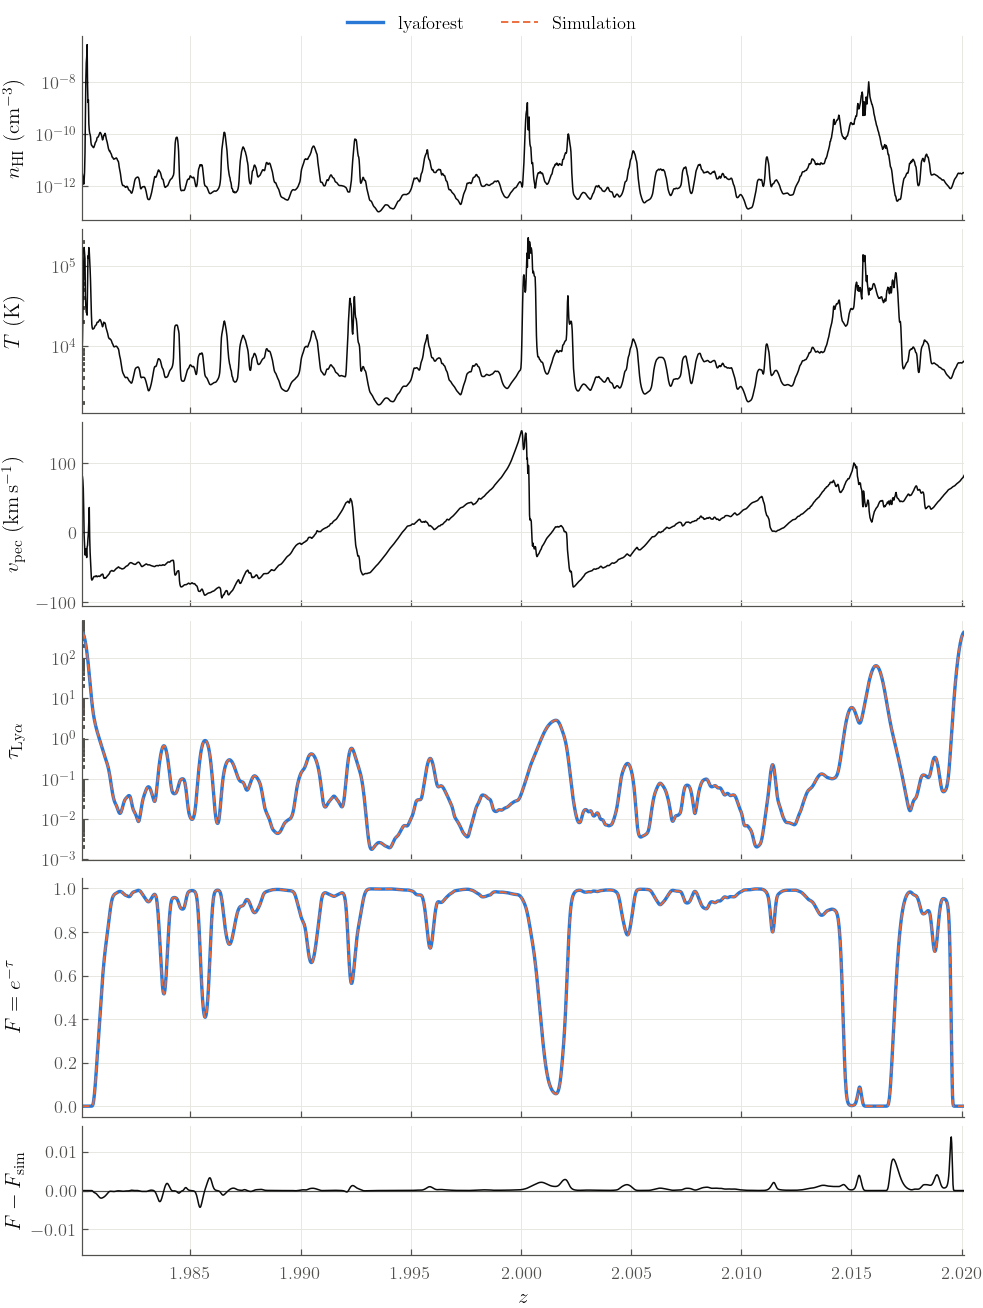

In [11]:
def plot_spectrum(skewer, tau):

    z = skewer['z']
    flux = np.exp(-tau)
    flux_sim = np.exp(-skewer['tau_sim'])

    fig, ax = plt.subplots(nrows=6, sharex=True, figsize=(9, 12), layout='constrained',
                           gridspec_kw={'height_ratios': [1, 1, 1, 1.3, 1.3, 0.7]})

    # Input fields
    ax[0].semilogy(z, skewer['n_HI'], c=INK, lw=1)
    ax[1].semilogy(z, skewer['T'], c=INK, lw=1)
    ax[2].plot(z, skewer['v_pec'], c=INK, lw=1)

    # Optical depth and flux: lyaforest (solid) vs simulation (dashed, drawn on top)
    ax[3].semilogy(z, tau, c=BLUE, lw=2.2, label='lyaforest')
    ax[3].semilogy(z, skewer['tau_sim'], c=ORANGE, lw=1.2, ls=(0, (4, 2)), label='Simulation')
    ax[4].plot(z, flux, c=BLUE, lw=2.2)
    ax[4].plot(z, flux_sim, c=ORANGE, lw=1.2, ls=(0, (4, 2)))

    # Residual
    ax[5].axhline(0, c=INK_LIGHT, lw=0.8)
    ax[5].plot(z, flux - flux_sim, c=INK, lw=1)
    lim = 1.2 * np.abs(flux - flux_sim).max()
    ax[5].set_ylim(-lim, lim)

    ax[0].set_ylabel(r'$n_\mathrm{HI}\ (\mathrm{cm}^{-3})$')
    ax[1].set_ylabel(r'$T\ (\mathrm{K})$')
    ax[2].set_ylabel(r'$v_\mathrm{pec}\ (\mathrm{km\,s^{-1}})$')
    ax[3].set_ylabel(r'$\tau_\mathrm{Ly\alpha}$')
    ax[4].set_ylabel(r'$F = e^{-\tau}$')
    ax[5].set_ylabel(r'$F - F_\mathrm{sim}$')
    ax[5].set_xlabel(r'$z$')
    ax[5].set_xlim(z.min(), z.max())

    fig.legend(*ax[3].get_legend_handles_labels(), loc='outside upper center', ncol=2)
    fig.align_ylabels(ax)

    return fig, ax

fig, ax = plot_spectrum(skewer, tau)
plt.show()

In [12]:
flux = np.exp(-tau)
flux_sim = np.exp(-tau_sim)
flux_diff = np.abs(flux - flux_sim)

print(f"Mean flux (lyaforest)       : {flux.mean():.4f}")
print(f"Mean flux (simulation)      : {flux_sim.mean():.4f}")
print(f"Median tau / tau_simulation : {np.median(tau / tau_sim):.4f}")
print(f"Max |flux difference|       : {flux_diff.max():.4f}")

Mean flux (lyaforest)       : 0.8156
Mean flux (simulation)      : 0.8151
Median tau / tau_simulation : 0.9942
Max |flux difference|       : 0.0138


The two agree across the whole skewer, including at the edges: the box is periodic, so the absorber at $z \approx 1.98$ also absorbs at the other end of the skewer.

## 3. Many skewers at once

Arrays of shape `(N_pixel, N_los)` give one optical depth per skewer. (For arrays stored as `(N_los, N_pixel)`, pass `axis=1`.)

In [13]:
skewers = lyaforest.read_skewer(redshift_key='3.0', skewer_indx=slice(None)) # all skewers in the file

tau = lyaforest.compute_tau(skewers['n_HI'], skewers['T'], skewers['v_pec'], skewers['z'], L_box=skewers['L_box'])

print(f"tau shape: {tau.shape}")
print(f"Mean flux over {tau.shape[1]} skewers: {np.exp(-tau).mean():.4f} (simulation: {np.exp(-skewers['tau_sim']).mean():.4f})")

tau shape: (2048, 10)
Mean flux over 10 skewers: 0.6560 (simulation: 0.6551)


## 4. Spectra at different redshifts

Sightline 0 at several snapshots. The intergalactic medium becomes more neutral at higher redshift, so the forest of absorption lines gets denser and the mean transmitted flux $\langle F \rangle$ drops.

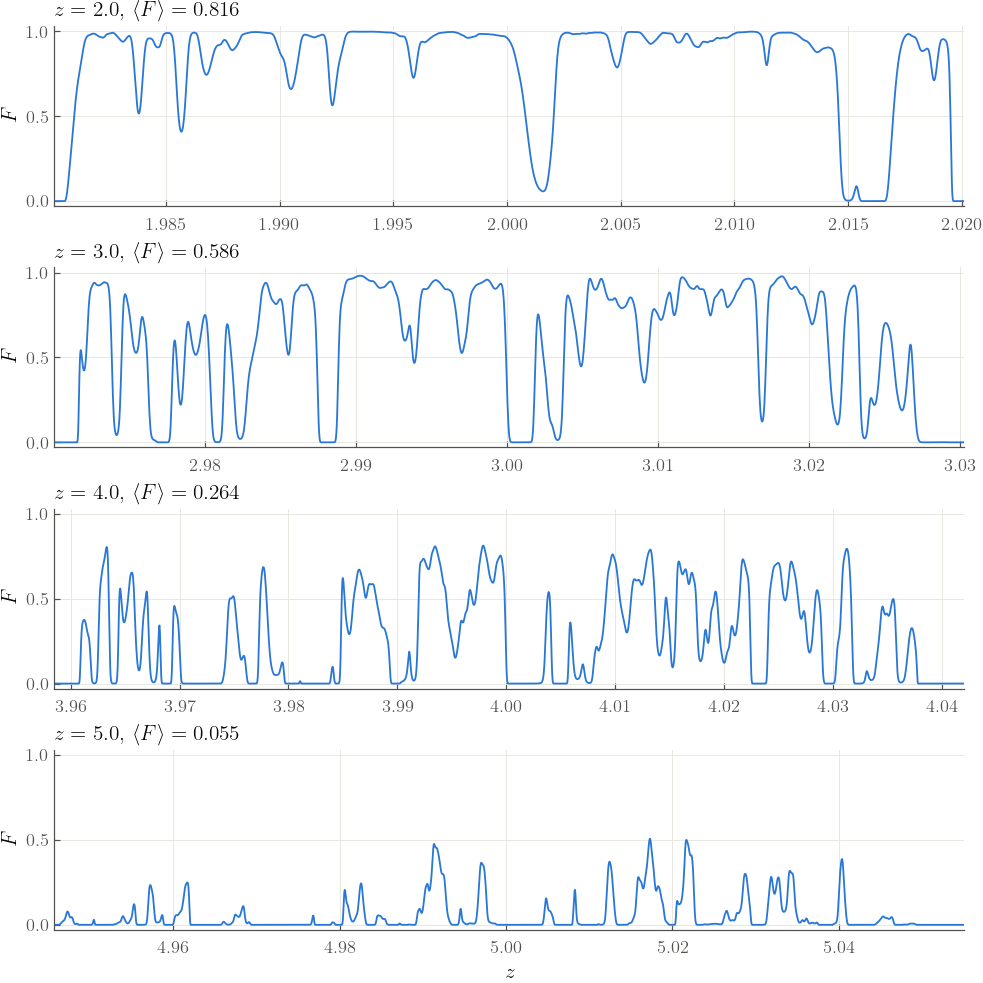

In [14]:
redshift_keys = ['2.0', '3.0', '4.0', '5.0']

fig, ax = plt.subplots(nrows=len(redshift_keys), sharey=True, figsize=(9, 9), layout='constrained')

for axis, key in zip(ax, redshift_keys):
    skewer = lyaforest.read_skewer(redshift_key=key, skewer_indx=0)
    tau = lyaforest.compute_tau(skewer['n_HI'], skewer['T'], skewer['v_pec'], skewer['z'], L_box=skewer['L_box'])
    flux = np.exp(-tau)
    axis.plot(skewer['z'], flux, c=BLUE, lw=1.2)
    axis.set_xlim(skewer['z'].min(), skewer['z'].max())
    axis.set_ylabel(r'$F$')
    axis.set_title(rf"$z = {key}$, $\langle F \rangle = {flux.mean():.3f}$", loc='left', color=INK)

ax[0].set_ylim(-0.03, 1.03)
ax[0].set_yticks([0, 0.5, 1])
ax[-1].set_xlabel(r'$z$')
plt.show()